# Violência de repetição contra pessoas LGBTQIAPN+ em São Paulo

**Aquenda · Global Solution 2026.2 · Inteligência Artificial & Machine Learning**

Giovanne Charelli Zaniboni Silva (RM 556223) · Gustavo Oliveira de Moura (RM 555827) · Lynn Bueno Rosa (RM 551102)

**Pergunta de ML:** quando uma pessoa LGBTQIAPN+ é atendida por violência na cidade de São Paulo,
dá para saber, com o que a ficha de notificação já registra, se essa violência **já aconteceu outras vezes**?

Violência que se repete quase sempre vem de alguém próximo, em casa ou na relação. É o caso que mais pede
acolhimento, rede de apoio e acompanhamento, que é o que o Aquenda oferece (casas de acolhimento, salas de conversa,
mapa de serviços). Um modelo que separe esses casos ajuda a rede a priorizar quem precisa de retorno.

**Dados:** notificações individuais de violência interpessoal do SINAN (Ministério da Saúde, DATASUS),
cidade de São Paulo, 2015 a 2024. Dados reais e públicos; nada simulado. Fonte e recorte em `dados/README.md`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
SEMENTE = 42
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COR = {"treino": "#5B8DB8", "teste": "#E07A3F", "cv": "#7A9E5A", "neutro": "#8A8A8A"}

def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", bbox_inches="tight"); plt.show()

## 1. Os dados

O arquivo vem de `preparar_dados.py`, que baixa os `VIOLBRaa.dbc` do FTP do DATASUS e guarda só o recorte:
notificações da cidade de São Paulo (código IBGE 355030) em que a pessoa atendida tem orientação homossexual ou
bissexual, ou identidade travesti, mulher trans ou homem trans.

In [2]:
bruto = pd.read_csv("dados/sinan_violencia_lgbt_sao_paulo_2015_2024.csv", dtype=str, keep_default_na=False)
# o arquivo de 2020 vem com NU_ANO em branco; o ano sai da data da notificação
bruto["ano"] = bruto["DT_NOTIFIC"].str[:4].astype(int)
print(f"{len(bruto):,} notificações, {bruto.shape[1]} colunas".replace(",", "."))
bruto["ano"].value_counts().sort_index().to_frame("notificações").T

16.178 notificações. 142 colunas


ano,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
notificações,205,533,702,1064,1268,1287,1921,2320,3451,3427


### Recorte da pergunta

- **Só violência interpessoal.** A ficha também registra lesão autoprovocada (`LES_AUTOP = 1`). Ela é outra pergunta,
  com outra rede de cuidado, e fica de fora.
- **Alvo:** `OUT_VEZES`, "ocorreu outras vezes?" (1 sim, 2 não). Fichas com 9 (ignorado) ou em branco saem,
  porque não dá para saber a resposta certa.

In [3]:
df = bruto[bruto["LES_AUTOP"] != "1"].copy()
print("sem lesão autoprovocada:", len(df))
print("OUT_VEZES:", df["OUT_VEZES"].replace("", "branco").value_counts().to_dict())
df = df[df["OUT_VEZES"].isin(["1", "2"])].copy()
df["alvo"] = (df["OUT_VEZES"] == "1").astype(int)
print(f"{len(df)} notificações com resposta; {df['alvo'].mean():.1%} são violência de repetição")

sem lesão autoprovocada: 10934
OUT_VEZES: {'2': 5363, '1': 4493, '9': 1037, 'branco': 41}
9856 notificações com resposta; 45.6% são violência de repetição


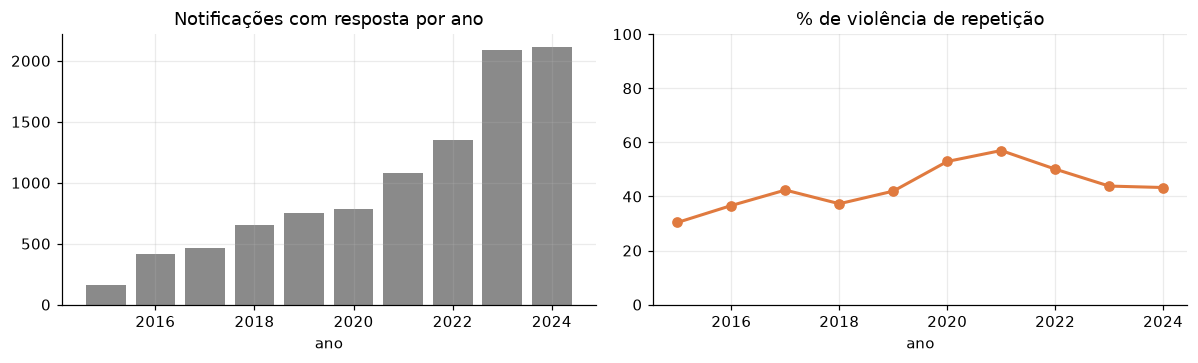

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
por_ano = df.groupby("ano")["alvo"].agg(["size", "mean"])
ax[0].bar(por_ano.index, por_ano["size"], color=COR["neutro"])
ax[0].set_title("Notificações com resposta por ano"); ax[0].set_xlabel("ano")
ax[1].plot(por_ano.index, por_ano["mean"] * 100, marker="o", color=COR["teste"], lw=2)
ax[1].set_title("% de violência de repetição"); ax[1].set_ylim(0, 100); ax[1].set_xlabel("ano")
salvar("01_alvo_por_ano")

## 2. Preparação

As variáveis vêm todas da ficha, preenchida no atendimento: quem é a pessoa, onde e como foi a violência e quem
é o provável autor. **Ficam de fora** os encaminhamentos (`ENC_*`, rede de saúde, delegacia, conselho tutelar...)
e a evolução do caso. Eles são decididos depois e às vezes por causa da repetição, então entregariam a resposta
ao modelo (vazamento).

Códigos do SINAN: nos campos de sim/não, 1 = sim, 2 = não, 9 = ignorado. Viram três colunas de informação:
`sim` (1/0) e `ignorado` (1/0) para não perder o fato de que o campo não foi preenchido.

In [5]:
SIM_NAO = ["DEF_TRANS", "VIOL_FISIC", "VIOL_PSICO", "VIOL_TORT", "VIOL_SEXU", "VIOL_FINAN", "VIOL_NEGLI",
           "VIOL_LEGAL", "VIOL_OUTR", "AG_FORCA", "AG_ENFOR", "AG_OBJETO", "AG_CORTE", "AG_QUENTE", "AG_ENVEN",
           "AG_FOGO", "AG_AMEACA", "AG_OUTROS", "REL_PAI", "REL_MAE", "REL_PAD", "REL_MAD", "REL_CONJ", "REL_EXCON",
           "REL_NAMO", "REL_EXNAM", "REL_FILHO", "REL_DESCO", "REL_IRMAO", "REL_CONHEC", "REL_CUIDA", "REL_PATRAO",
           "REL_INST", "REL_POL", "REL_PROPRI", "REL_OUTROS", "AUTOR_ALCO"]
CATEGORICAS = {
    "CS_RACA": {"1": "branca", "2": "preta", "3": "amarela", "4": "parda", "5": "indígena"},
    "LOCAL_OCOR": {"01": "residência", "02": "habitação coletiva", "03": "escola", "04": "esporte", "05": "bar",
                   "06": "via pública", "07": "comércio", "08": "indústria", "09": "outro"},
    "AUTOR_SEXO": {"1": "masculino", "2": "feminino", "3": "ambos"},
    "NUM_ENVOLV": {"1": "um", "2": "dois ou mais"},
    "SIT_CONJUG": {"1": "solteira(o)", "2": "casada(o)/união", "3": "viúva(o)", "4": "separada(o)"},
    "CICL_VID": {"1": "criança", "2": "adolescente", "3": "jovem", "4": "adulto", "5": "idoso"},
    "VIOL_MOTIV": {"01": "sexismo", "02": "LGBTfobia", "03": "racismo", "04": "religiosa", "05": "xenofobia",
                   "06": "geracional", "07": "situação de rua", "08": "deficiência", "09": "outros"},
    "CS_SEXO": {"M": "masculino", "F": "feminino"},
}

def idade_em_anos(v):
    # NU_IDADE_N: 4xxx = anos; 1, 2 e 3 = horas, dias e meses (menos de 1 ano)
    if len(v) == 4 and v.isdigit():
        return int(v[1:]) if v[0] == "4" else 0
    return np.nan

def escolaridade(v):
    # 00 analfabeto ... 08 superior completo; 09 ignorado; 10 não se aplica
    return int(v) if v.isdigit() and int(v) <= 8 else np.nan

def hora(v):
    return int(v[:2]) if len(v) >= 2 and v[:2].isdigit() and int(v[:2]) < 24 else np.nan

def montar(d):
    X = {}  # junta as colunas num dicionário e monta a tabela de uma vez
    X["idade"] = d["NU_IDADE_N"].map(idade_em_anos)
    X["escolaridade"] = d["CS_ESCOL_N"].map(escolaridade)
    X["hora"] = d["HORA_OCOR"].map(hora)
    X["noite"] = X["hora"].between(18, 23) | X["hora"].between(0, 5)
    X["lgb"] = d["ORIENT_SEX"].isin(["2", "3"]).astype(int)
    X["bissexual"] = (d["ORIENT_SEX"] == "3").astype(int)
    X["trans"] = d["IDENT_GEN"].isin(["1", "2", "3"]).astype(int)
    X["travesti"] = (d["IDENT_GEN"] == "1").astype(int)
    for c in SIM_NAO:
        X[c.lower()] = (d[c] == "1").astype(int)
        X[c.lower() + "_ign"] = (d[c] == "9").astype(int)
    for c, nomes in CATEGORICAS.items():
        for cod, nome in nomes.items():
            X[f"{c.lower()}={nome}"] = (d[c] == cod).astype(int)
    # resumo do vínculo com o autor: família, parceria íntima, desconhecido
    X["autor_familia"] = d[["REL_PAI", "REL_MAE", "REL_PAD", "REL_MAD", "REL_IRMAO", "REL_FILHO"]].eq("1").any(axis=1).astype(int)
    X["autor_parceria"] = d[["REL_CONJ", "REL_EXCON", "REL_NAMO", "REL_EXNAM"]].eq("1").any(axis=1).astype(int)
    X["n_tipos_violencia"] = d[["VIOL_FISIC", "VIOL_PSICO", "VIOL_TORT", "VIOL_SEXU", "VIOL_FINAN", "VIOL_NEGLI"]].eq("1").sum(axis=1)
    X["noite"] = X["noite"].astype(int)
    return pd.DataFrame(X, index=d.index).astype(float)

X_todo = montar(df)
y_todo = df["alvo"].to_numpy()
print(X_todo.shape[1], "variáveis")
X_todo.describe().T[["mean", "min", "max"]].head(12)

124 variáveis


,mean,min,max
idade,28.779119,10.0,94.0
escolaridade,5.283017,0.0,8.0
hora,12.214574,0.0,23.0
noite,0.343750,0.0,1.0
lgb,0.707082,0.0,1.0
bissexual,0.185268,0.0,1.0
trans,0.451400,0.0,1.0
travesti,0.066863,0.0,1.0
def_trans,0.100852,0.0,1.0
def_trans_ign,0.042005,0.0,1.0


### Valores faltantes

Idade, escolaridade e hora podem faltar. O XGBoost trata o faltante na própria árvore: aprende para que lado
mandá-lo. Para a regressão logística (a referência), o faltante vira a mediana do **treino**, dentro do pipeline.

In [6]:
falta = X_todo[["idade", "escolaridade", "hora"]].isna().mean().mul(100).round(1)
falta.to_frame("% faltante").T

,idade,escolaridade,hora
% faltante,0.0,14.6,39.7


### Divisão treino e teste: pelo tempo

O modelo seria usado em casos novos. Então o teste é o futuro: **treino com 2015 a 2023, teste com 2024.**
Assim, o resultado também mostra se o padrão de 2015 vale para hoje. Uma divisão aleatória misturaria anos e
daria uma nota otimista.

A busca de hiperparâmetros usa validação cruzada estratificada de 5 partes **só no treino**. O teste fica
guardado até o fim e é usado uma vez.

In [7]:
treino = (df["ano"] <= 2023).to_numpy()
X_tr, X_te = X_todo[treino], X_todo[~treino]
y_tr, y_te = y_todo[treino], y_todo[~treino]
resumo = pd.DataFrame({"notificações": [len(y_tr), len(y_te)], "% repetição": [y_tr.mean() * 100, y_te.mean() * 100]},
                      index=["treino 2015–2023", "teste 2024"]).round(1)
resumo

,notificações,% repetição
treino 2015–2023,7743,46.2
teste 2024,2113,43.3


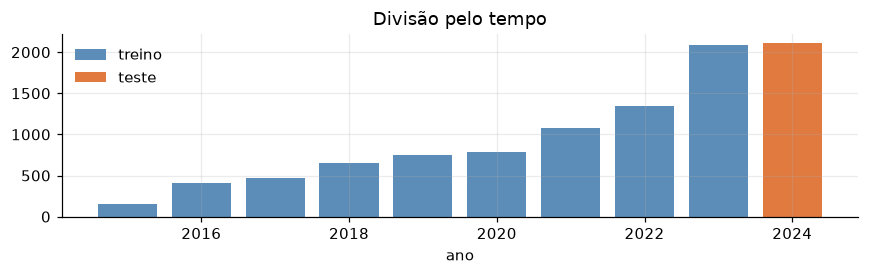

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for nome, m, cor in [("treino", treino, COR["treino"]), ("teste", ~treino, COR["teste"])]:
    cont = df[m].groupby("ano").size()
    ax.bar(cont.index, cont.values, color=cor, label=nome)
ax.legend(frameon=False); ax.set_title("Divisão pelo tempo"); ax.set_xlabel("ano")
salvar("02_divisao_temporal")

## 3. Modelo

**XGBoost (árvores com gradient boosting).** Por quê:

- os dados são tabulares e quase todos binários (sim/não da ficha): árvores são o modelo que melhor rende nesse formato;
- o efeito não é aditivo: ser violência psicológica **e** vir da parceria diz mais do que cada um sozinho, e as árvores
  pegam essas combinações;
- trata faltante sem precisar inventar valor;
- dá para ler o que pesou na decisão (importância e contribuição por variável).

MLP e LSTM não se justificam: não há sequência no tempo para a mesma pessoa e o volume é pequeno para rede neural.
KMeans não responde à pergunta, que é supervisionada. Para saber se o XGBoost vale a pena, ele é comparado com um
modelo que chuta sempre a classe mais comum e com uma regressão logística.

**Métrica principal: ROC-AUC.** Mede se o modelo põe os casos de repetição na frente dos outros, sem depender do
limiar e sem ser enganada pela proporção das classes. Junto: PR-AUC, acurácia balanceada, precisão, recall e F1.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
METRICAS_CV = {"auc": "roc_auc", "pr_auc": "average_precision", "bal_acc": "balanced_accuracy"}

referencias = {
    "sempre a classe mais comum": DummyClassifier(strategy="most_frequent"),
    "regressão logística": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
}
linhas = []
for nome, modelo in referencias.items():
    r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=METRICAS_CV, return_train_score=True)
    linhas.append({"modelo": nome, "AUC treino": r["train_auc"].mean(), "AUC validação": r["test_auc"].mean(),
                   "PR-AUC validação": r["test_pr_auc"].mean()})
pd.DataFrame(linhas).set_index("modelo").round(3)

,AUC treino,AUC validação,PR-AUC validação
modelo,,,
sempre a classe mais comum,0.500,0.50,0.462
regressão logística,0.808,0.79,0.759


## 4. Treino com diferentes hiperparâmetros

Três hiperparâmetros do XGBoost, **36 combinações** (4 × 3 × 3), cada uma avaliada com validação cruzada de 5 partes
no treino:

| Hiperparâmetro | O que controla | Valores |
|---|---|---|
| `max_depth` | quantas perguntas cada árvore faz seguidas (complexidade) | 2, 3, 4, 6 |
| `learning_rate` | quanto cada árvore nova corrige a anterior | 0.03, 0.1, 0.3 |
| `n_estimators` | quantas árvores | 100, 300, 600 |

O resto fica fixo: `subsample = 0.8`, `colsample_bytree = 0.8` e `min_child_weight = 5`, um pouco de aleatoriedade e
de cuidado contra decorar casos raros. Para cada combinação, guardamos a AUC no treino (as partes usadas para
ajustar) e na validação (a parte deixada de fora). A diferença entre as duas é o sinal de overfitting.

In [10]:
from itertools import product

GRADE = {"max_depth": [2, 3, 4, 6], "learning_rate": [0.03, 0.1, 0.3], "n_estimators": [100, 300, 600]}
BASE = dict(subsample=0.8, colsample_bytree=0.8, min_child_weight=5, eval_metric="logloss",
            tree_method="hist", random_state=SEMENTE, n_jobs=-1)

resultados = []
for md_, lr, n in product(GRADE["max_depth"], GRADE["learning_rate"], GRADE["n_estimators"]):
    modelo = XGBClassifier(max_depth=md_, learning_rate=lr, n_estimators=n, **BASE)
    r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=METRICAS_CV, return_train_score=True)
    resultados.append({"max_depth": md_, "learning_rate": lr, "n_estimators": n,
                       "auc_treino": r["train_auc"].mean(), "auc_val": r["test_auc"].mean(), "auc_val_dp": r["test_auc"].std(),
                       "pr_auc_val": r["test_pr_auc"].mean(), "bal_acc_val": r["test_bal_acc"].mean()})
grade = pd.DataFrame(resultados)
grade["distancia"] = grade["auc_treino"] - grade["auc_val"]
print(len(grade), "combinações avaliadas")
grade.sort_values("auc_val", ascending=False).head(10).round(3)

36 combinações avaliadas


,max_depth,learning_rate,n_estimators,auc_treino,auc_val,auc_val_dp,pr_auc_val,bal_acc_val,distancia
28,6,0.03,300,0.898,0.811,0.007,0.793,0.739,0.087
19,4,0.03,300,0.855,0.811,0.010,0.791,0.741,0.044
20,4,0.03,600,0.880,0.810,0.009,0.792,0.738,0.069
11,3,0.03,600,0.852,0.810,0.009,0.790,0.740,0.041
27,6,0.03,100,0.859,0.809,0.009,0.791,0.736,0.049
30,6,0.10,100,0.899,0.809,0.007,0.792,0.738,0.090
21,4,0.10,100,0.856,0.809,0.008,0.790,0.741,0.047
10,3,0.03,300,0.834,0.808,0.010,0.788,0.743,0.026
29,6,0.03,600,0.935,0.807,0.006,0.790,0.739,0.128
13,3,0.10,300,0.867,0.807,0.007,0.787,0.738,0.061


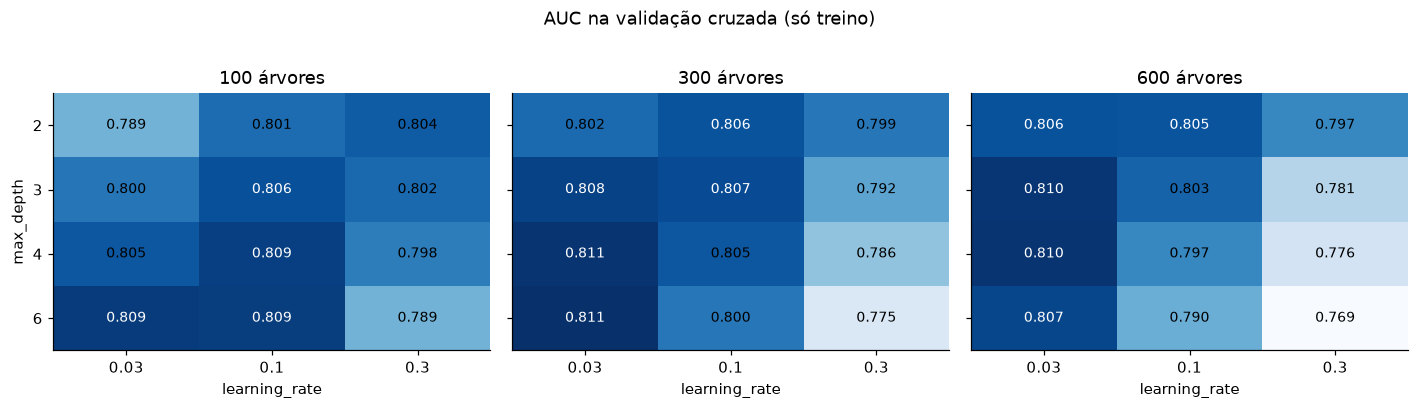

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, n in zip(axes, GRADE["n_estimators"]):
    t = grade[grade.n_estimators == n].pivot(index="max_depth", columns="learning_rate", values="auc_val")
    im = ax.imshow(t.values, cmap="Blues", vmin=grade.auc_val.min(), vmax=grade.auc_val.max(), aspect="auto")
    ax.set_xticks(range(len(t.columns)), t.columns); ax.set_yticks(range(len(t.index)), t.index)
    ax.set_xlabel("learning_rate"); ax.set_title(f"{n} árvores"); ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if t.values[i, j] > grade.auc_val.quantile(0.6) else "black")
axes[0].set_ylabel("max_depth")
fig.suptitle("AUC na validação cruzada (só treino)", y=1.02)
salvar("03_grade_auc_validacao")

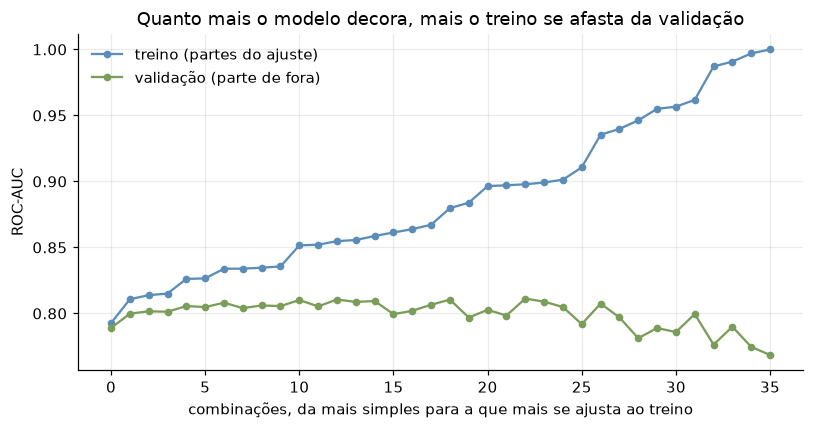

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ordem = grade.sort_values("auc_treino").reset_index(drop=True)
x = np.arange(len(ordem))
ax.plot(x, ordem["auc_treino"], "o-", color=COR["treino"], ms=4, label="treino (partes do ajuste)")
ax.plot(x, ordem["auc_val"], "o-", color=COR["cv"], ms=4, label="validação (parte de fora)")
ax.set_xlabel("combinações, da mais simples para a que mais se ajusta ao treino")
ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False); ax.set_title("Quanto mais o modelo decora, mais o treino se afasta da validação")
salvar("04_overfitting_grade")

### Escolha da combinação

Pegamos a combinação com a maior AUC na validação. Se outra mais simples ficar a menos de um desvio-padrão dela,
fica a mais simples: rende igual e generaliza melhor.

In [13]:
melhor = grade.loc[grade.auc_val.idxmax()]
toleravel = grade[grade.auc_val >= melhor.auc_val - melhor.auc_val_dp]
escolhida = toleravel.sort_values(["max_depth", "n_estimators", "learning_rate"]).iloc[0]
PARAMS = {"max_depth": int(escolhida.max_depth), "learning_rate": float(escolhida.learning_rate),
          "n_estimators": int(escolhida.n_estimators)}
print("melhor na validação:", melhor[["max_depth", "learning_rate", "n_estimators", "auc_val"]].to_dict())
print("escolhida (a mais simples dentro de 1 desvio):", PARAMS, f"AUC validação {escolhida.auc_val:.3f}")

melhor na validação: {'max_depth': 6.0, 'learning_rate': 0.03, 'n_estimators': 300.0, 'auc_val': 0.8112336698558004}
escolhida (a mais simples dentro de 1 desvio): {'max_depth': 2, 'learning_rate': 0.3, 'n_estimators': 100} AUC validação 0.804


## 5. Resultados em treino e teste

O modelo escolhido é treinado de novo com todo o treino (2015–2023) e avaliado uma única vez no teste (2024).

O limiar de decisão sai do treino e não do teste: é o limiar que maximiza o F1 nas previsões da validação cruzada.

In [14]:
from sklearn.model_selection import cross_val_predict

modelo = XGBClassifier(**PARAMS, **BASE)
p_oof = cross_val_predict(modelo, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
limiares = np.linspace(0.2, 0.8, 61)
LIMIAR = float(limiares[np.argmax([f1_score(y_tr, p_oof >= l) for l in limiares])])
modelo.fit(X_tr, y_tr)
print(f"limiar escolhido no treino: {LIMIAR:.2f}")

def avaliar(y, p):
    yh = (p >= LIMIAR).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "acurácia balanceada": balanced_accuracy_score(y, yh), "precisão": precision_score(y, yh),
            "recall": recall_score(y, yh), "F1": f1_score(y, yh)}

p_tr, p_te = modelo.predict_proba(X_tr)[:, 1], modelo.predict_proba(X_te)[:, 1]
logistica = referencias["regressão logística"].fit(X_tr, y_tr)
tabela = pd.DataFrame({
    "XGBoost · treino": avaliar(y_tr, p_tr),
    "XGBoost · validação cruzada": avaliar(y_tr, p_oof),
    "XGBoost · teste": avaliar(y_te, p_te),
    "logística · teste": avaliar(y_te, logistica.predict_proba(X_te)[:, 1]),
}).T.round(3)
tabela

limiar escolhido no treino: 0.35


,ROC-AUC,PR-AUC,acurácia balanceada,precisão,recall,F1
XGBoost · treino,0.830,0.812,0.742,0.670,0.840,0.745
XGBoost · validação cruzada,0.804,0.780,0.727,0.658,0.821,0.730
XGBoost · teste,0.798,0.754,0.719,0.617,0.833,0.709
logística · teste,0.789,0.745,0.703,0.600,0.824,0.695


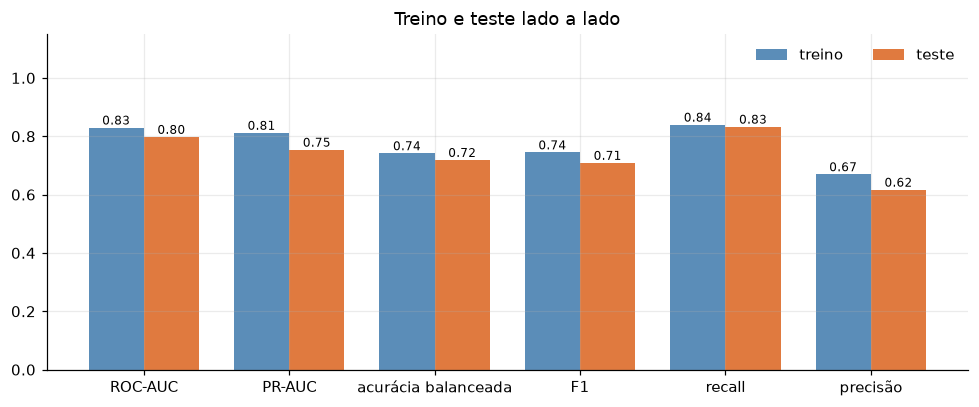

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
mostrar = ["ROC-AUC", "PR-AUC", "acurácia balanceada", "F1", "recall", "precisão"]
w = 0.38; x = np.arange(len(mostrar))
for k, (nome, cor) in enumerate([("XGBoost · treino", COR["treino"]), ("XGBoost · teste", COR["teste"])]):
    v = tabela.loc[nome, mostrar].values
    ax.bar(x + (k - 0.5) * w, v, w, color=cor, label=nome.split(" · ")[1])
    for xi, vi in zip(x + (k - 0.5) * w, v):
        ax.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, mostrar); ax.set_ylim(0, 1.15); ax.legend(frameon=False, loc="upper right", ncol=2)
ax.set_title("Treino e teste lado a lado")
salvar("05_treino_vs_teste")

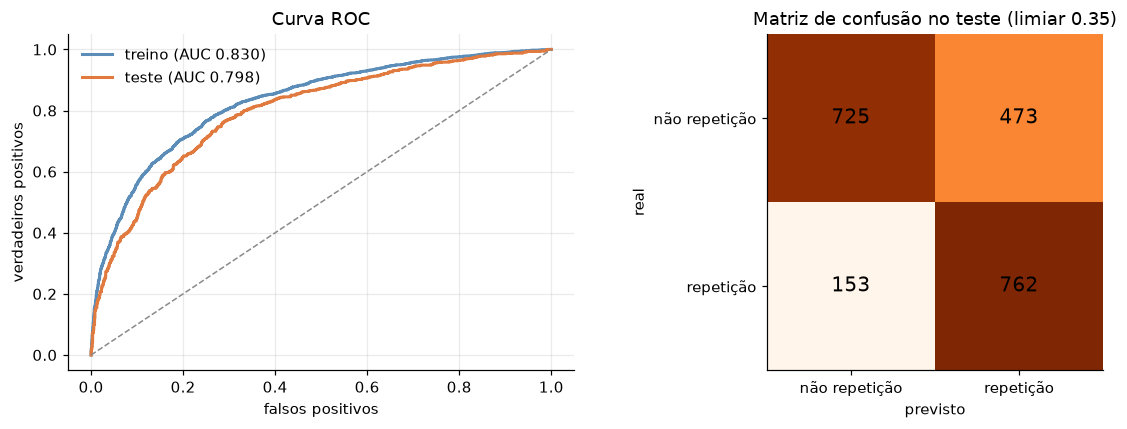

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nome, y, p, cor in [("treino", y_tr, p_tr, COR["treino"]), ("teste", y_te, p_te, COR["teste"])]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color=COR["neutro"], lw=1)
ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("verdadeiros positivos"); ax[0].legend(frameon=False)
ax[0].set_title("Curva ROC")
cm = confusion_matrix(y_te, (p_te >= LIMIAR).astype(int))
ax[1].imshow(cm, cmap="Oranges"); ax[1].grid(False)
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13, color="black")
ax[1].set_xticks([0, 1], ["não repetição", "repetição"]); ax[1].set_yticks([0, 1], ["não repetição", "repetição"])
ax[1].set_xlabel("previsto"); ax[1].set_ylabel("real"); ax[1].set_title(f"Matriz de confusão no teste (limiar {LIMIAR:.2f})")
salvar("06_roc_e_confusao")

### Overfitting

Três leituras:

1. **Na grade:** com árvores rasas, treino e validação ficam juntos. Com `max_depth = 6`, muitas árvores e passo alto,
   a AUC no treino sobe e a da validação para ou cai: o modelo começa a decorar as fichas do treino.
2. **No escolhido:** a distância entre treino e validação mostra quanto ainda sobra de ajuste ao treino.
3. **No teste:** a queda do treino para o teste junta duas coisas, o overfitting e a mudança no tempo
   (2024 não é igual a 2015–2023). A curva abaixo separa as duas: uma é a profundidade, a outra é o ano.

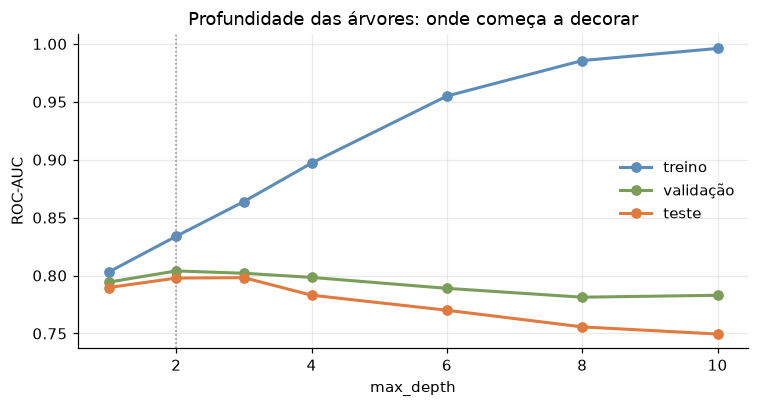

max_depth,1,2,3,4,6,8,10
treino,0.803,0.834,0.864,0.897,0.955,0.986,0.996
validação,0.794,0.804,0.802,0.798,0.789,0.781,0.783
teste,0.790,0.798,0.798,0.783,0.770,0.756,0.750


In [17]:
prof = []
for d in [1, 2, 3, 4, 6, 8, 10]:
    m = XGBClassifier(max_depth=d, learning_rate=PARAMS["learning_rate"], n_estimators=PARAMS["n_estimators"], **BASE)
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring="roc_auc", return_train_score=True)
    m.fit(X_tr, y_tr)
    prof.append({"max_depth": d, "treino": r["train_score"].mean(), "validação": r["test_score"].mean(),
                 "teste": roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])})
prof = pd.DataFrame(prof).set_index("max_depth")
fig, ax = plt.subplots(figsize=(7, 3.8))
for c, cor in [("treino", COR["treino"]), ("validação", COR["cv"]), ("teste", COR["teste"])]:
    ax.plot(prof.index, prof[c], "o-", color=cor, lw=2, label=c)
ax.axvline(PARAMS["max_depth"], color=COR["neutro"], ls=":", lw=1)
ax.set_xlabel("max_depth"); ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False)
ax.set_title("Profundidade das árvores: onde começa a decorar")
salvar("07_curva_profundidade")
prof.round(3).T

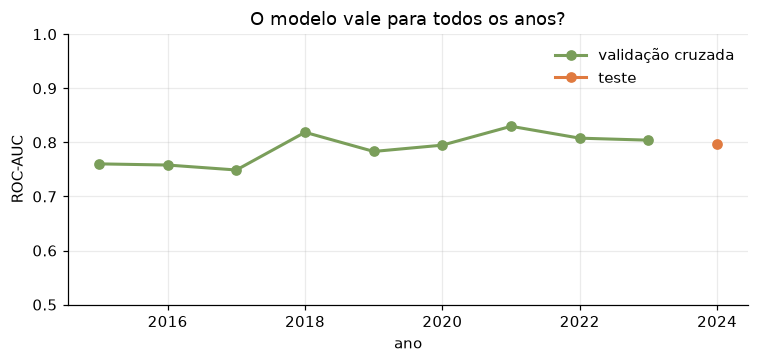

,ano,parte,notificações,% repetição,AUC
0,2015,validação cruzada,158.0,30.380,0.760
1,2016,validação cruzada,412.0,36.650,0.758
2,2017,validação cruzada,465.0,42.366,0.749
3,2018,validação cruzada,654.0,37.309,0.819
4,2019,validação cruzada,753.0,41.965,0.783
5,2020,validação cruzada,784.0,52.934,0.795
6,2021,validação cruzada,1081.0,56.984,0.830
7,2022,validação cruzada,1351.0,50.111,0.808
8,2023,validação cruzada,2085.0,43.837,0.804
9,2024,teste,2113.0,43.303,0.798


In [18]:
# AUC por ano: nos anos do treino, com as previsões da validação cruzada (o modelo não viu aquela ficha);
# em 2024, com o modelo final. Mostra se o padrão muda com o tempo.
anos = pd.concat([
    pd.DataFrame({"ano": df.loc[treino, "ano"].to_numpy(), "y": y_tr, "p": p_oof, "parte": "validação cruzada"}),
    pd.DataFrame({"ano": df.loc[~treino, "ano"].to_numpy(), "y": y_te, "p": p_te, "parte": "teste"}),
])
por_ano = anos.groupby(["ano", "parte"]).apply(
    lambda g: pd.Series({"notificações": len(g), "% repetição": g.y.mean() * 100, "AUC": roc_auc_score(g.y, g.p)}),
    include_groups=False).reset_index()
fig, ax = plt.subplots(figsize=(7, 3.4))
for parte, cor in [("validação cruzada", COR["cv"]), ("teste", COR["teste"])]:
    t = por_ano[por_ano.parte == parte]
    ax.plot(t.ano, t.AUC, "o-", color=cor, lw=2, label=parte)
ax.set_ylim(0.5, 1); ax.set_ylabel("ROC-AUC"); ax.set_xlabel("ano"); ax.legend(frameon=False)
ax.set_title("O modelo vale para todos os anos?")
salvar("08_auc_por_ano")
por_ano.round(3)

## 6. O que pesa na previsão

A contribuição de cada variável vem do próprio XGBoost (`pred_contribs`, a mesma ideia do SHAP): quanto ela empurra
cada previsão para "repetição" ou para "não". A média do valor absoluto, nas fichas do teste, diz o quanto ela importa.
O sinal médio, nas fichas em que a variável vale 1, diz para que lado ela puxa.

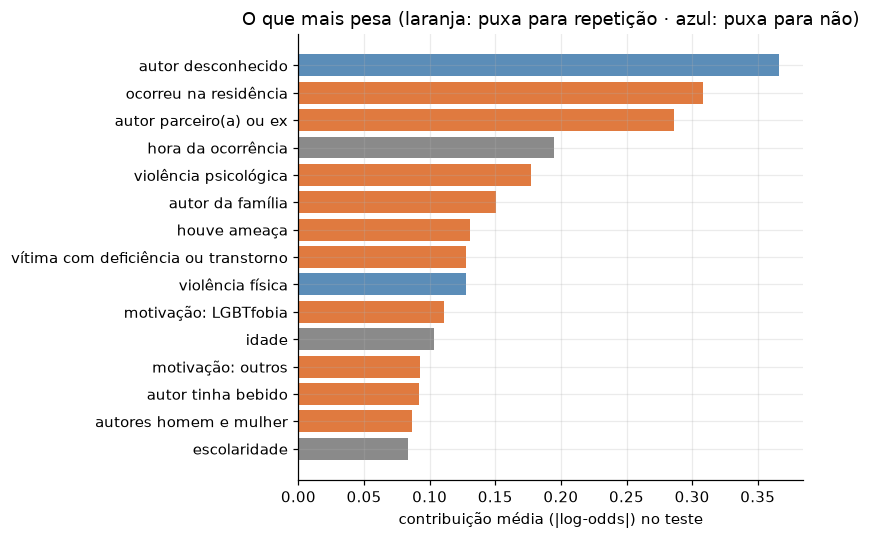

,variável,importância,puxa para
0,autor desconhecido,0.366,não repetição
1,ocorreu na residência,0.309,repetição
2,autor parceiro(a) ou ex,0.286,repetição
3,hora da ocorrência,0.195,—
4,violência psicológica,0.177,repetição
5,autor da família,0.150,repetição
6,houve ameaça,0.131,repetição
7,vítima com deficiência ou transtorno,0.128,repetição
8,violência física,0.127,não repetição
9,motivação: LGBTfobia,0.111,repetição


In [19]:
import xgboost as xgb
contrib = modelo.get_booster().predict(xgb.DMatrix(X_te), pred_contribs=True)[:, :-1]
imp = pd.DataFrame({"variável": X_te.columns, "importância": np.abs(contrib).mean(axis=0)})
lado = []
for j, c in enumerate(X_te.columns):
    marcados = X_te[c].to_numpy() == 1
    lado.append(contrib[marcados, j].mean() if marcados.any() and set(np.unique(X_te[c].dropna())) <= {0, 1} else np.nan)
imp["puxa para"] = np.where(np.array(lado) > 0, "repetição", np.where(np.array(lado) < 0, "não repetição", "—"))
LEGIVEL = {"rel_desco": "autor desconhecido", "local_ocor=residência": "ocorreu na residência",
           "autor_parceria": "autor parceiro(a) ou ex", "hora": "hora da ocorrência", "viol_psico": "violência psicológica",
           "autor_familia": "autor da família", "ag_ameaca": "houve ameaça", "def_trans": "vítima com deficiência ou transtorno",
           "viol_fisic": "violência física", "viol_motiv=LGBTfobia": "motivação: LGBTfobia", "idade": "idade",
           "viol_motiv=outros": "motivação: outros", "autor_alco": "autor tinha bebido", "autor_sexo=ambos": "autores homem e mulher",
           "escolaridade": "escolaridade", "viol_sexu": "violência sexual", "local_ocor=via pública": "ocorreu na via pública",
           "rel_conhec": "autor conhecido", "trans": "pessoa trans ou travesti", "num_envolv=dois ou mais": "dois ou mais autores",
           "rel_mae": "autora: mãe", "rel_pai": "autor: pai", "rel_conj": "autor: cônjuge", "rel_excon": "autor: ex-cônjuge",
           "viol_finan": "violência financeira", "viol_negli": "negligência", "ag_forca": "força corporal", "n_tipos_violencia": "nº de tipos de violência"}
imp["variável"] = imp["variável"].map(lambda v: LEGIVEL.get(v, v))
top = imp.sort_values("importância", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7.5, 5))
cores = [COR["teste"] if l == "repetição" else COR["treino"] if l == "não repetição" else COR["neutro"] for l in top["puxa para"]]
ax.barh(top["variável"][::-1], top["importância"][::-1], color=cores[::-1])
ax.set_xlabel("contribuição média (|log-odds|) no teste")
ax.set_title("O que mais pesa (laranja: puxa para repetição · azul: puxa para não)")
salvar("09_importancia")
top.reset_index(drop=True).round(3)

In [20]:
def taxa(mascara):
    return f"{y_todo[mascara].mean():.0%} ({mascara.sum()} fichas)"
grupos = {
    "autor da família": X_todo["autor_familia"] == 1,
    "autor parceiro(a) ou ex": X_todo["autor_parceria"] == 1,
    "autor desconhecido": X_todo["rel_desco"] == 1,
    "na residência": X_todo["local_ocor=residência"] == 1,
    "na via pública": X_todo["local_ocor=via pública"] == 1,
    "violência psicológica": X_todo["viol_psico"] == 1,
    "motivação LGBTfobia": X_todo["viol_motiv=LGBTfobia"] == 1,
    "pessoa trans ou travesti": X_todo["trans"] == 1,
}
pd.Series({k: taxa(v.to_numpy()) for k, v in grupos.items()}, name="% de repetição").to_frame()

,% de repetição
autor da família,72% (1667 fichas)
autor parceiro(a) ou ex,66% (2390 fichas)
autor desconhecido,20% (2870 fichas)
na residência,63% (4577 fichas)
na via pública,27% (2517 fichas)
violência psicológica,61% (2720 fichas)
motivação LGBTfobia,50% (1508 fichas)
pessoa trans ou travesti,48% (4449 fichas)


## 7. Conclusão para quem usa a cidade

As conclusões em número estão no `RELATORIO_ML.md`, que lê as tabelas acima. Em resumo:

- **A repetição tem rosto conhecido.** Quando o autor é da família ou é parceiro(a) e a violência é em casa, a chance
  de ser repetição é muito maior do que quando o autor é desconhecido na rua. Para uma pessoa LGBTQIAPN+, isso quer
  dizer que o perigo maior pode estar onde ela mora. É para essa pessoa que existem as casas de acolhimento e a
  sala "família" do Aquenda.
- **O modelo separa bem melhor do que o acaso**, e o resultado se mantém em 2024, ano que ele não viu. Mas ele erra
  uma parte dos casos. Ele **não serve para decidir o atendimento de alguém**. Serve para a rede planejar: priorizar
  retorno e acompanhamento nas fichas com perfil de repetição, e para o app mostrar primeiro acolhimento e rede de
  apoio a quem está nessa situação.
- **Limites:** é dado de notificação. Só aparece quem chegou a um serviço de saúde e teve a ficha preenchida, e muita
  violência contra pessoas LGBTQIAPN+ nunca é notificada. Orientação e identidade de gênero ficam como "ignorado" em
  boa parte das fichas, então o recorte é menor do que a realidade.

In [21]:
import json
Path("modelo").mkdir(exist_ok=True)
modelo.save_model("modelo/xgboost_repeticao.json")
json.dump({"parametros": PARAMS, "limiar": round(LIMIAR, 2), "variaveis": list(X_tr.columns),
           "treino": "2015-2023", "teste": "2024",
           "metricas_teste": tabela.loc["XGBoost · teste"].round(4).to_dict(),
           "metricas_treino": tabela.loc["XGBoost · treino"].round(4).to_dict()},
          open("modelo/metadados.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
grade.round(4).to_csv("modelo/grade_hiperparametros.csv", index=False)
print("modelo e grade salvos em ml/modelo/")

modelo e grade salvos em ml/modelo/
